# Chapter 14: Distributions

Companion notebook for *Master Data Visualization: A Hands-On Beginner's Guide with Python, Matplotlib, Seaborn & Plotly*.

Run the cells from top to bottom (**Kernel → Restart Kernel and Run All Cells**). The data files this chapter uses are in the same folder as this notebook.

## 14.1 Histograms with `histplot()`

In [1]:
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

sns.set_theme(style='ticks')
plt.style.use('book.mplstyle')

In [2]:
orders = pd.read_csv('orders.csv')
orders.head(3)

,order_id,weekday,hour,region,order_value,delivery_days
0,1001,Thu,20,East,88,7
1,1002,Wed,15,East,93,4
2,1003,Wed,18,South,246,6


### `sns.histplot()`

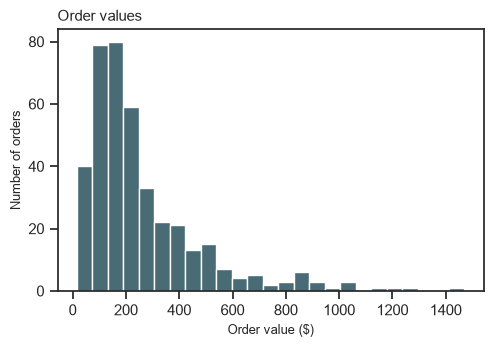

In [3]:
ax = sns.histplot(data=orders, x='order_value')
ax.set(title='Order values', xlabel='Order value ($)',
       ylabel='Number of orders')
plt.show()

### `bins=` and `binwidth=`

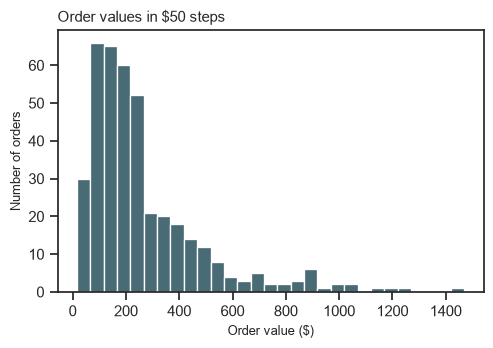

In [4]:
ax = sns.histplot(data=orders, x='order_value', binwidth=50)
ax.set(title='Order values in $50 steps', xlabel='Order value ($)',
       ylabel='Number of orders')
plt.show()

### `stat=`

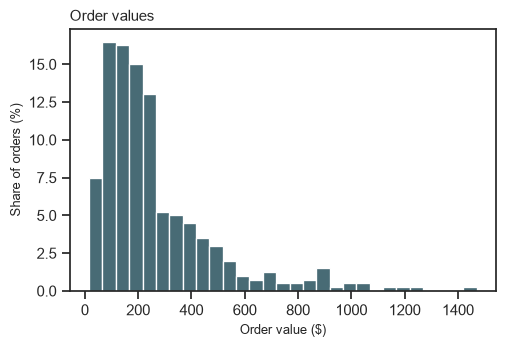

In [5]:
ax = sns.histplot(data=orders, x='order_value', binwidth=50,
                  stat='percent')
ax.set(title='Order values', xlabel='Order value ($)',
       ylabel='Share of orders (%)')
plt.show()

### `discrete=True`

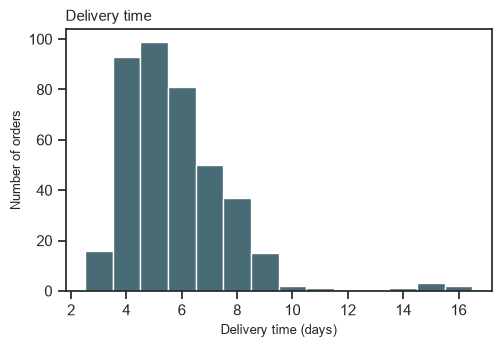

In [6]:
ax = sns.histplot(data=orders, x='delivery_days', discrete=True)
ax.set(title='Delivery time', xlabel='Delivery time (days)',
       ylabel='Number of orders')
plt.show()

## 14.2 Comparing Groups

In [7]:
two = orders[orders['region'].isin(['North', 'West'])]

### `multiple='layer'`

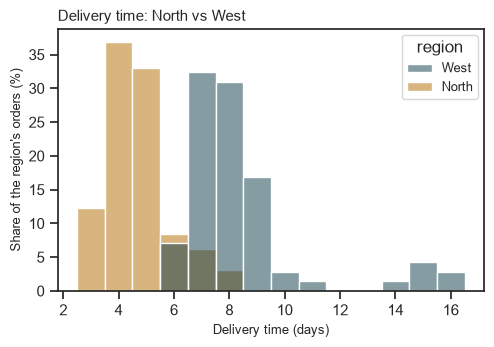

In [8]:
ax = sns.histplot(data=two, x='delivery_days', hue='region',
                  discrete=True, stat='percent', common_norm=False)
ax.set(title='Delivery time: North vs West',
       xlabel='Delivery time (days)',
       ylabel="Share of the region's orders (%)")
plt.show()

### `element='step'`

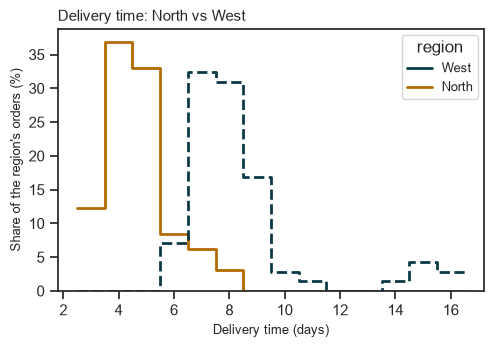

In [9]:
ax = sns.histplot(data=two, x='delivery_days', hue='region',
                  discrete=True, stat='percent', common_norm=False,
                  element='step', fill=False)
ax.set(title='Delivery time: North vs West',
       xlabel='Delivery time (days)',
       ylabel="Share of the region's orders (%)")
plt.show()

### `multiple='stack'`

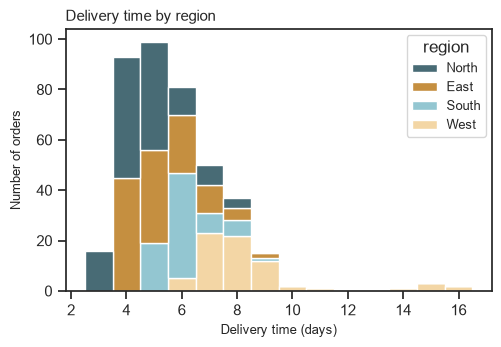

In [10]:
regions = ['North', 'East', 'South', 'West']
ax = sns.histplot(data=orders, x='delivery_days', hue='region',
                  hue_order=regions, discrete=True,
                  multiple='stack')
ax.set(title='Delivery time by region', xlabel='Delivery time (days)',
       ylabel='Number of orders')
plt.show()

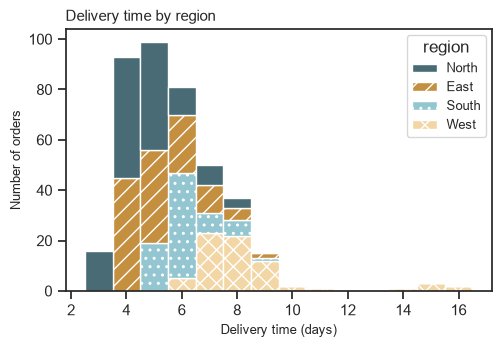

In [11]:
ax = sns.histplot(data=orders, x='delivery_days', hue='region',
                  hue_order=regions, discrete=True,
                  multiple='stack')
ax.set(title='Delivery time by region', xlabel='Delivery time (days)',
       ylabel='Number of orders')
hatches = ['', '//', '..', 'xx']
for bars, hatch in zip(reversed(ax.containers), hatches):
    for bar in bars:
        bar.set_hatch(hatch)
for handle, hatch in zip(ax.get_legend().legend_handles, hatches):
    handle.set_hatch(hatch)
plt.show()

### `multiple='fill'`

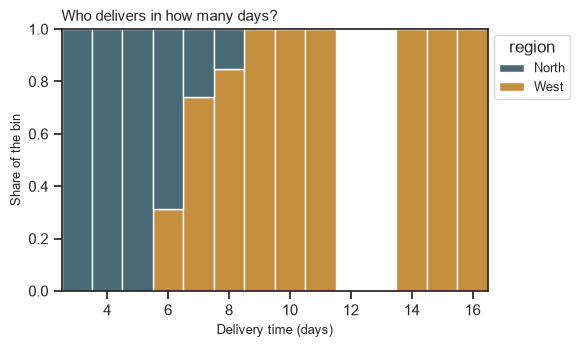

In [12]:
ax = sns.histplot(data=two, x='delivery_days', hue='region',
                  hue_order=['North', 'West'], discrete=True,
                  multiple='fill')
ax.set(title='Who delivers in how many days?',
       xlabel='Delivery time (days)', ylabel='Share of the bin')
sns.move_legend(ax, 'upper left', bbox_to_anchor=(1, 1))
plt.show()

## 14.3 Two-Dimensional Histograms

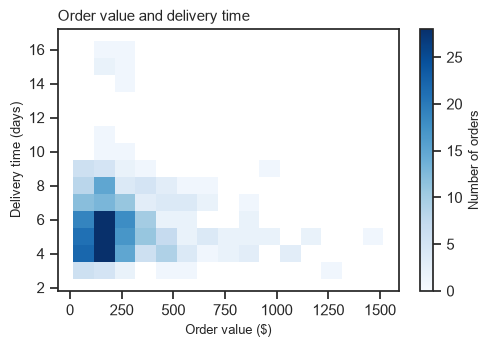

In [13]:
ax = sns.histplot(data=orders, x='order_value', y='delivery_days',
                  binwidth=(100, 1), discrete=(False, True),
                  cmap='Blues', cbar=True,
                  cbar_kws={'label': 'Number of orders'})
ax.set(title='Order value and delivery time',
       xlabel='Order value ($)', ylabel='Delivery time (days)')
plt.show()

## 14.4 Density Curves with `kdeplot()`

### `sns.kdeplot()`

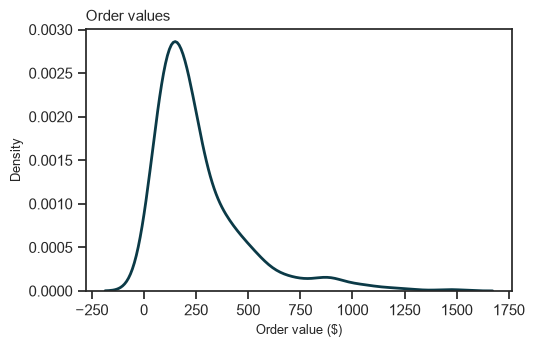

In [14]:
ax = sns.kdeplot(data=orders, x='order_value', linestyle='-')
ax.set(title='Order values', xlabel='Order value ($)',
       ylabel='Density')
plt.show()

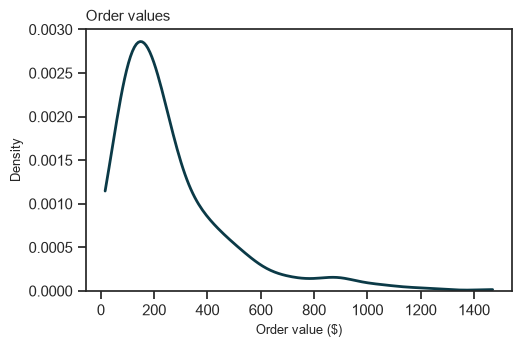

In [15]:
ax = sns.kdeplot(data=orders, x='order_value', cut=0,
                 linestyle='-')
ax.set(title='Order values', xlabel='Order value ($)',
       ylabel='Density')
plt.show()

### `bw_adjust=`

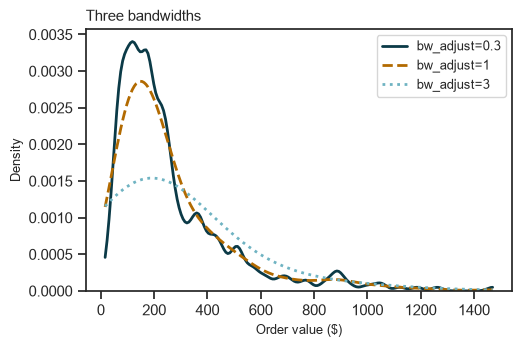

In [16]:
fig, ax = plt.subplots()
for bw, dash in zip([0.3, 1, 3], ['-', '--', ':']):
    sns.kdeplot(data=orders, x='order_value', cut=0, bw_adjust=bw,
                linestyle=dash, label=f'bw_adjust={bw}', ax=ax)
ax.set(title='Three bandwidths', xlabel='Order value ($)',
       ylabel='Density')
ax.legend()
plt.show()

### Comparing groups with `hue=`

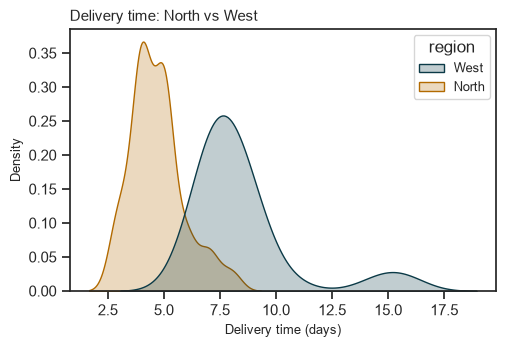

In [17]:
ax = sns.kdeplot(data=two, x='delivery_days', hue='region',
                 common_norm=False, fill=True)
ax.set(title='Delivery time: North vs West',
       xlabel='Delivery time (days)', ylabel='Density')
plt.show()

## 14.5 Figure-Level Histograms with `displot()`

### `sns.displot()`

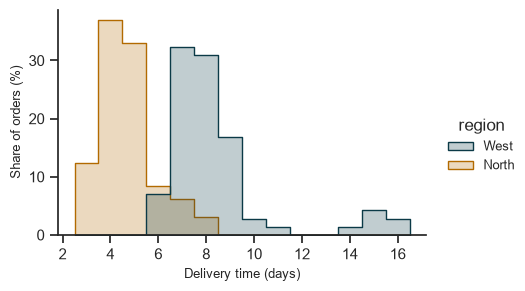

In [18]:
g = sns.displot(data=two, x='delivery_days', hue='region',
                kind='hist', discrete=True, stat='percent',
                common_norm=False, element='step',
                height=3, aspect=1.5)
g.set_axis_labels('Delivery time (days)', "Share of orders (%)")
plt.show()

## 14.6 Two Distributions at Once with `jointplot()`

### `sns.jointplot()`

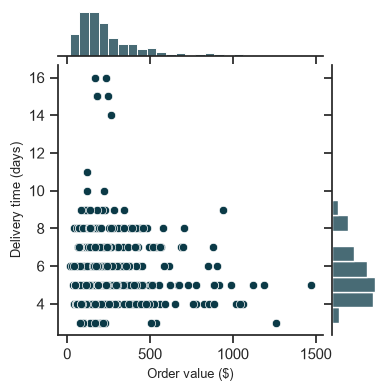

In [19]:
g = sns.jointplot(data=orders, x='order_value', y='delivery_days',
                  height=4)
g.set_axis_labels('Order value ($)', 'Delivery time (days)')
plt.show()

### `kind=`

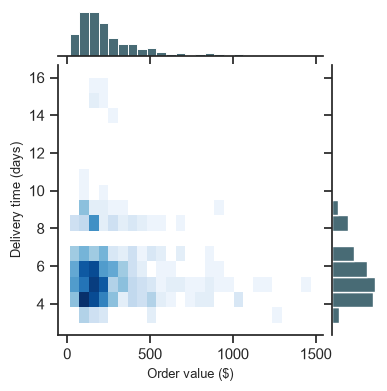

In [20]:
g = sns.jointplot(data=orders, x='order_value', y='delivery_days',
                  kind='hist', cmap='Blues', height=4)
g.set_axis_labels('Order value ($)', 'Delivery time (days)')
plt.show()

### `hue=` in a jointplot

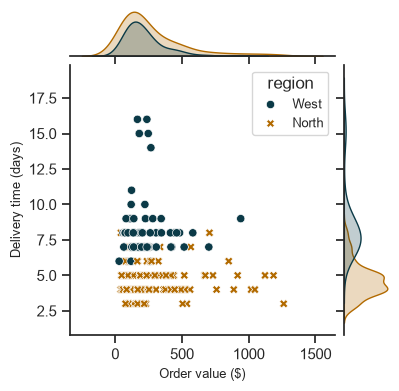

In [21]:
g = sns.jointplot(data=two, x='order_value', y='delivery_days',
                  hue='region', joint_kws={'style': two['region']},
                  height=4)
g.set_axis_labels('Order value ($)', 'Delivery time (days)')
plt.show()